# Hypotheses

Dans ce modèle, tout agent de la population suit le processus suivant :

1. Un push tag permet à l’étudiant de placer son code dans une file d’attente FIFO infinie pour l’exécution de la test-suite associée : un nombre K de serveurs est disponible pour cette tâche.

### File 1 : M/M/K
On utilise une file (infinie) markovienne en entrée et en sortie pour simuler les push des etudiants. On dispose également de K serveur pour cette première file. 


| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ|
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ |
| K | K serveurs identiques traitent des tests en parallèle, soit une capacité de traitement de K·μ |


2. Une fois la test-suite exécutée, le résultat est placé dans une file d’attente FIFO infinie gérée par un serveur unique pour l’envoi vers le front.
   
### File 2 : M/M/1
On utilise également une file (infine) markovienne en entrée et en sortie mais cette fois ci elle ne contient qu'un seul serveur.

| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ|
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ |
| 1 | 1 serveur récupère les résultats des tests pour l'envoyer au front, soit une capacité de traitement de μ |


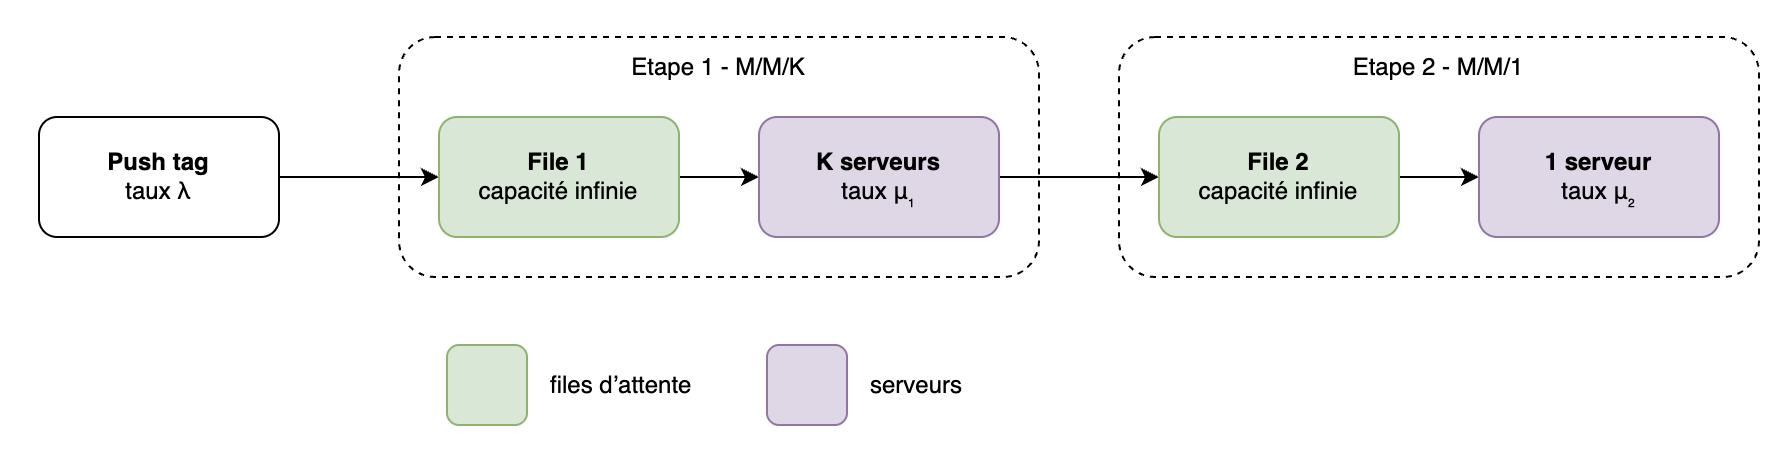

In [21]:
from IPython.display import Image
Image("images/1.png")

# Simulation 1

Consigne : Proposez un système d’attente modélisant le contexte décrit ci-dessus. Effectuez quelques simulations pour analyser son comportement selon les paramètres en jeu. 

In [11]:
import heapq

import numpy as np
import pandas as pd


class waterfall_simulation_1():
    """
    A class representing the waterfall tandem queue : M/M/K (test-suite) followed by M/M/1 (front).

    Each push enters file 1, is served by one of the K servers, then its result enters file 2 and
    is sent to the front by the single server. Both queues are FIFO with infinite capacity, so no
    agent is ever lost.

    Attributes :

        lamda (float)      : parameter of exponential law corresponding to interarrival times.
        mu1 (float)        : parameter of exponential law corresponding to service times of file 1.
        K (int)            : number of servers of file 1.
        mu2 (float)        : parameter of exponential law corresponding to service times of file 2.
        gen (np.random)    : a random generator
        t_size (int)       : number of arrivals simulated.
        tops1              : dataframe of file 1 times for each agent, filled by run_mmk.
        tops2              : dataframe of file 2 times for each agent, filled by run_mm1.
        tops               : dataframe of both files times for each agent, filled by run.
    """


    def __init__(self, lamda, mu1, K, mu2, gen, test_z=100) :
        """
        Initializes a new instance of the class waterfall_simulation_1.

        Args :
            lamda  : parameter of exponential law corresponding to interarrival times.
            mu1    : parameter of exponential law corresponding to service times of file 1.
            K      : number of servers of file 1.
            mu2    : parameter of exponential law corresponding to service times of file 2.
            gen    : a random generator
            test_z : test size.
        """

        self.lamda = lamda
        self.mu1 = mu1
        self.K = K
        self.mu2 = mu2
        self.gen = gen
        self.t_size = test_z

        self.tops1 = None
        self.tops2 = None
        self.tops = None

    def _poisson_arrivals(self):
        """
        Returns the absolute arrival times of a Poisson process of intensity lamda, indexed by agent.
        """
        return pd.Series(np.cumsum(self.gen.exponential(1.0 / self.lamda, self.t_size)))

    def _simulate_queue(self, t_arrivals, mu, n_servers):
        """
        Simulates an infinite FIFO queue with n_servers identical exponential servers.

        Args :
            t_arrivals : series of queue arrival times, indexed by agent.
            mu         : parameter of exponential law corresponding to service times.
            n_servers  : number of servers.

        Returns :
            A dataframe indexed by agent, sorted by queue arrival time, containing queue arrival times
            (t_arval_queue), service arrival times (t_arval_srv), departure times (t_depart_sys),
            sojourn (t_sojourn), waiting (t_waiting) and service (t_service) times.
        """
        t_arrivals = t_arrivals.sort_values()
        t_arval_queue = t_arrivals.to_numpy()
        n = len(t_arval_queue)
        services = self.gen.exponential(1.0 / mu, n)

        t_arval_srv = np.zeros(n)
        t_depart_sys = np.zeros(n)

        free_at = [0.0] * n_servers

        for i, t in enumerate(t_arval_queue):
            t_arval_srv[i] = max(t, free_at[0])
            t_depart_sys[i] = t_arval_srv[i] + services[i]
            heapq.heapreplace(free_at, t_depart_sys[i])

        tops = pd.DataFrame({
            't_arval_queue': t_arval_queue,
            't_arval_srv': t_arval_srv,
            't_depart_sys': t_depart_sys
        }, index=t_arrivals.index)
        tops.index.name = 'agent'

        tops['t_sojourn'] = tops['t_depart_sys'] - tops['t_arval_queue']
        tops['t_waiting'] = tops['t_arval_srv'] - tops['t_arval_queue']
        tops['t_service'] = tops['t_depart_sys'] - tops['t_arval_srv']
        return tops

    def run_mmk(self):
        """
        Simulates file 1 alone, an M/M/K queue fed by a Poisson process of intensity lamda.

        Fills the attribute tops1.
        """
        self.tops = None
        self.tops1 = self._simulate_queue(self._poisson_arrivals(), self.mu1, self.K)

    def run_mm1(self, t_arrivals=None):
        """
        Simulates file 2 alone, an M/M/1 queue.

        Fills the attribute tops2.

        Args :
            t_arrivals : series of queue arrival times, indexed by agent. If None, arrivals follow a
                         Poisson process of intensity lamda.
        """
        if t_arrivals is None:
            t_arrivals = self._poisson_arrivals()

        self.tops = None
        self.tops2 = self._simulate_queue(t_arrivals, self.mu2, 1)

    def run(self):
        """
        Simulates the whole system : the departures of file 1 are the arrivals of file 2.

        Fills tops1, tops2 and tops. The dataframe tops has one row per push and contains the columns
        of both files, suffixed by 1 or 2, and the total durations t_sojourn, t_waiting and t_service.
        """
        self.run_mmk()
        self.run_mm1(self.tops1['t_depart_sys'])

        tops = self.tops1.join(self.tops2, lsuffix='1', rsuffix='2')
        tops['t_sojourn'] = tops['t_depart_sys2'] - tops['t_arval_queue1']
        tops['t_waiting'] = tops['t_waiting1'] + tops['t_waiting2']
        tops['t_service'] = tops['t_service1'] + tops['t_service2']
        self.tops = tops

    def _stages(self, file):
        """
        Returns the list of per-file dataframes matching file (1, 2 or None for the whole system).
        """
        if file not in (None, 1, 2):
            raise ValueError("file must be 1, 2 or None")

        stages = {None: [self.tops1, self.tops2], 1: [self.tops1], 2: [self.tops2]}[file]
        missing = self.tops is None if file is None else stages[0] is None
        if missing:
            method = {None: 'run', 1: 'run_mmk', 2: 'run_mm1'}[file]
            raise RuntimeError(f"call {method}() first")
        return stages

    @staticmethod
    def _count_between(t_start, t_end, time_steps):
        """
        Counts, at each time step, the agents such that t_start <= t < t_end.
        """
        started = np.searchsorted(np.sort(t_start), time_steps, side='right')
        ended = np.searchsorted(np.sort(t_end), time_steps, side='right')
        return started - ended

    def counts(self, t_intervals, file=None):
        """
        Computes number of agents in system at all given times.

        Args :
            t_intervals : size of time laps between two successive tops.
            file        : 1 or 2 for a single file, None for the whole system (both queues, both services).

        Returns :
            A dataframe indexed by time laps of size t_intervals all along total queue simulation time,
            its three columns contain number of agents in system (ag_in_sys), in arrival queue (ag_in_queue) and
            in service (ag_in_service).
        """
        stages = self._stages(file)
        max_time = max(tops['t_depart_sys'].max() for tops in stages)
        time_steps = np.arange(0, max_time + t_intervals, t_intervals)

        ag_in_queue = sum(self._count_between(tops['t_arval_queue'], tops['t_arval_srv'], time_steps) for tops in stages)
        ag_in_service = sum(self._count_between(tops['t_arval_srv'], tops['t_depart_sys'], time_steps) for tops in stages)

        counts_df = pd.DataFrame({
            'ag_in_sys': ag_in_queue + ag_in_service,
            'ag_in_queue': ag_in_queue,
            'ag_in_service': ag_in_service
        }, index=time_steps)
        counts_df.index.name = 'time'
        return counts_df

    def stats(self, file=None):
        """
        Computes statistics of a current simulation of queue.

        Args :
            file : 1 or 2 for a single file, None for the whole system.

        Returns:
            A dataframe indexed by standard statistics of interest mean sojourn time (mean_sojourn_time),
            mean waiting time (mean_waiting_time) and mean service time (mean_service_time).
        """
        stages = self._stages(file)
        tops = self.tops if file is None else stages[0]

        stat_values = [
            tops['t_sojourn'].mean(),
            tops['t_waiting'].mean(),
            tops['t_service'].mean()
        ]
        stat_names = ['mean_sojourn_time', 'mean_waiting_time', 'mean_service_time']
        return pd.DataFrame(stat_values, index=stat_names, columns=['value'])

In [ ]:
import numpy as np

rng = np.random.default_rng(seed=42)
simu = waterfall_simulation_1(2, 3, 2, 2, rng, test_z=100)
simu.run()
simu_counts = simu.counts(t_intervals=0.5)
simu.stats()

/var/folders/4p/vctrwwjn75s5vyw4_1d33tdr0000gn/T/ipykernel_38272/3781000235.py:135: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  tops = self.tops1.join(self.tops2, lsuffix='1', rsuffix='2')


,value
mean_sojourn_time,5.434199
mean_waiting_time,4.621158
mean_service_time,0.813041


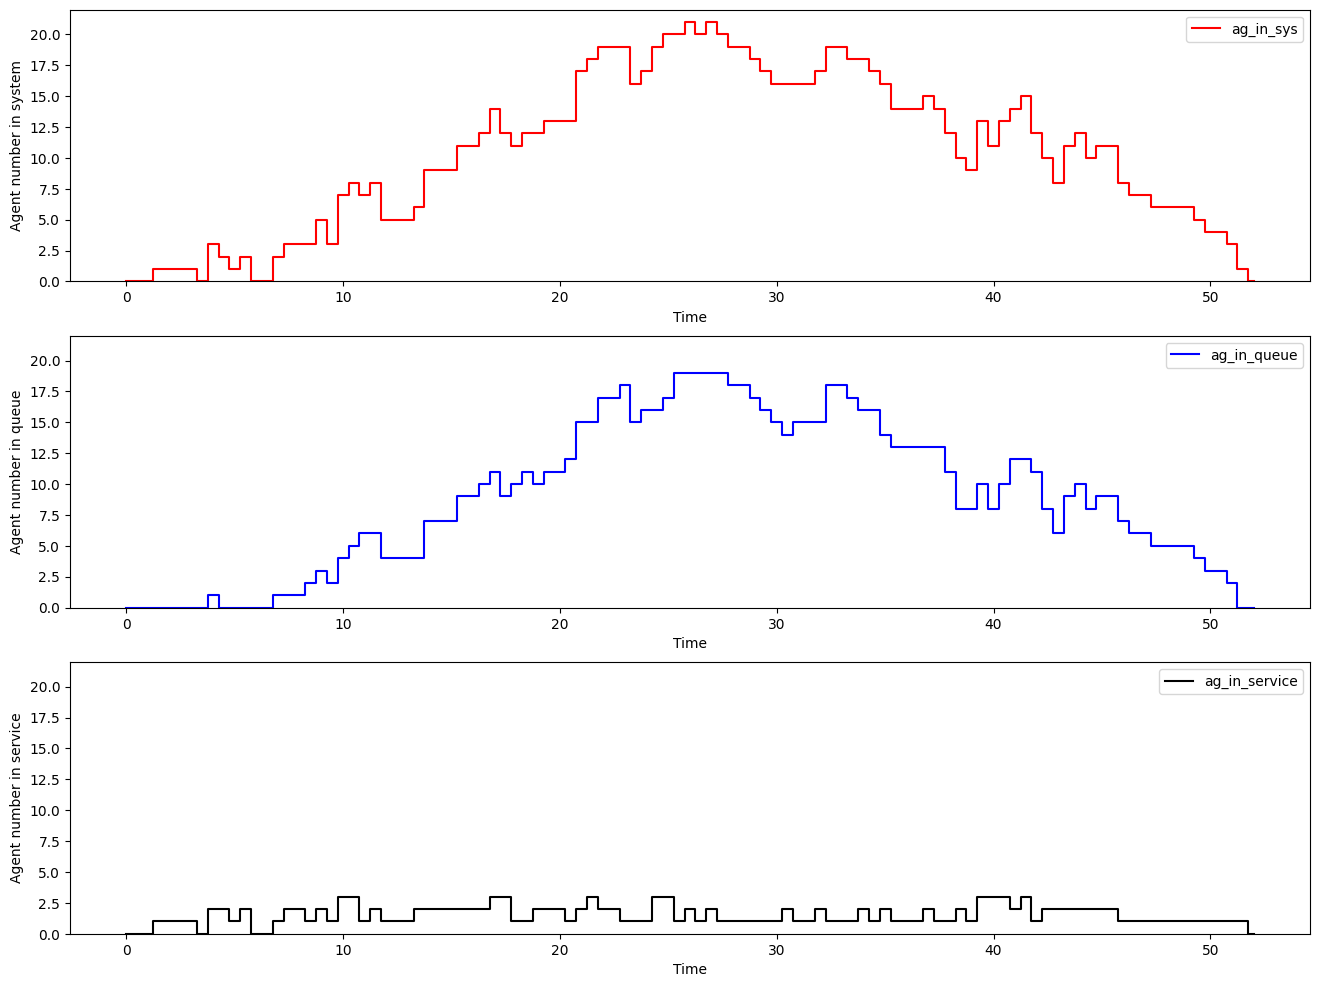

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(16, 12))
counts = ['ag_in_sys','ag_in_queue','ag_in_service']
labels = ['system', 'queue', 'service']
colors = ['red', 'blue', 'black']

for i in range(3):
    simu_counts.plot(y= counts[i],
                   use_index=True, ax=axes[i], linewidth=1.5,drawstyle='steps-mid', color=f'{colors[i]}',
                   ylabel=f'Agent number in {labels[i]}', xlabel='Time', ylim=[0,max(simu_counts['ag_in_sys']+1)])


/var/folders/4p/vctrwwjn75s5vyw4_1d33tdr0000gn/T/ipykernel_38272/3781000235.py:135: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  tops = self.tops1.join(self.tops2, lsuffix='1', rsuffix='2')


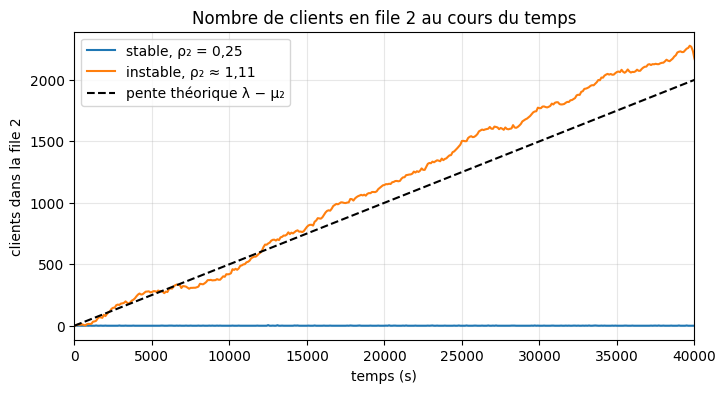

In [19]:
REF = dict(lam=0.5, mu1=1/60, K=40, mu2=2.0)
fig, ax = plt.subplots(figsize=(8, 4))
for mu2, lab in [(2.0, 'stable, ρ₂ = 0,25'), (0.45, 'instable, ρ₂ ≈ 1,11')]:
    s = waterfall_simulation_1(REF['lam'], REF['mu1'], REF['K'], mu2, np.random.default_rng(0), test_z=20_000)
    s.run()
    c = s.counts(100, file=2)
    ax.plot(c.index, c.ag_in_sys, label=lab)
t = np.linspace(0, 40_000, 2)
ax.plot(t, (REF['lam'] - 0.45) * t, 'k--', label='pente théorique λ − μ₂')
ax.set(xlabel='temps (s)', ylabel='clients dans la file 2', title='Nombre de clients en file 2 au cours du temps', xlim=(0, 40_000))
ax.legend(); ax.grid(alpha=.3)
plt.show()

Si ρ₂ > 1 (ici 1,11), la file 2 grossit en permanence, avec une pente λ − μ₂ : environ 2 000 clients en attente après 40 000 s. Le système n'atteint pas de régime stationnaire, donc le temps de séjour ne se stabilise pas.